01 – Data audit
Load the raw occupancy events, check data quality, and choose `max_hold` from the gap distribution.

## 1. Setup
Adds `../src` to the import path so the notebook can use the project's own `occforecast` package, imports the analysis libraries, and sets the path to the raw occupancy file. The raw data is not stored in the repository (see `data/README.md`).

In [1]:
import sys
sys.path.insert(0, "../src")          # so we can import our own package

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from occforecast.load import load_occupancy, audit

DATA = "../data/raw/5occupancySensor_MayToDec2024_9MRows.csv"

## 2. Load and validate the raw events
`load_occupancy` reads the CSV in 1M-row chunks, keeping only the four columns needed (space ID, timestamp, status, headcount). It drops rows with an unparseable timestamp, a missing space ID, a negative headcount or an unknown status, converts all times to UTC, and sorts the events by space and time, because the raw file is not in time order. The load is timed as a performance baseline.

**Result:** 9,091,732 rows read, 0 dropped. Load time is about 12.7 s.

In [2]:
t0 = time.perf_counter()
events = load_occupancy(DATA)
print(f"Loaded in {time.perf_counter() - t0:.1f} s")
print(f"Rows read: {events.attrs['n_raw']:,}   dropped: {events.attrs['n_dropped']:,}   kept: {len(events):,}")

Loaded in 12.7 s
Rows read: 9,091,732   dropped: 0   kept: 9,091,732


## 3. Data-quality audit per space
`audit` summarises each space: number of events, date range, maximum headcount, longest gap between events, duplicate timestamps, and rows where status and headcount disagree (e.g. `CurrentlyOccupied` with headcount 0).

**Findings:**
- 5 spaces, 1.5–2.2M events each. Four cover Nov 2023 / Mar 2024 to Apr 2026; one stops in Dec 2024.
- Zero status/headcount mismatches across all 9.09M rows, so the headcount column is internally consistent.
- 9 duplicate timestamps in total (negligible; the latest is kept during resampling).
- Some very long silences, up to 375 h (15.6 days), which need a handling rule (Section 5).

In [3]:
report = audit(events)
report

,events,start,end,max_headcount,longest_gap_h,duplicate_times,status_mismatch
space,,,,,,,
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2169461,2023-11-23 13:37:32+00:00,2026-04-22 13:02:18+00:00,40,373.727778,0,0
227f1068-9e41-469f-bef0-275f27a0bdba,1500394,2024-03-03 04:06:30+00:00,2026-04-22 12:09:42+00:00,38,26.199444,3,0
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,1551583,2024-04-30 14:00:16+00:00,2024-12-30 12:01:56+00:00,36,15.477778,1,0
941f0352-bb69-47d0-a9c5-ac29eb4f7319,1975423,2023-11-23 13:36:52+00:00,2026-04-22 13:02:38+00:00,15,374.939444,1,0
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,1894871,2024-03-03 04:06:30+00:00,2026-04-22 12:54:50+00:00,72,87.276667,4,0


## 4. Distribution of gaps between events
Computes the time between consecutive events within each space and plots it on log-log axes, so both the very common short gaps and the rare long ones are visible.

**Findings:** the median gap is 4 s, 90% of gaps are under 34 s, and 99% are under 4.7 min. The spikes at 2 s and 4 s show the sensor's 2-second reporting tick. The tail extends to about 1–2 days (nights and weekends), with a handful of isolated longer gaps that look like outages. (The two ~375 h gaps fall beyond the plot's right edge.)

count    9.091727e+06
mean     5.648942e-01
std      1.473952e+01
min      0.000000e+00
50%      6.666667e-02
90%      5.666667e-01
99%      4.733333e+00
99.9%    6.020913e+01
max      2.249637e+04
Name: time, dtype: float64


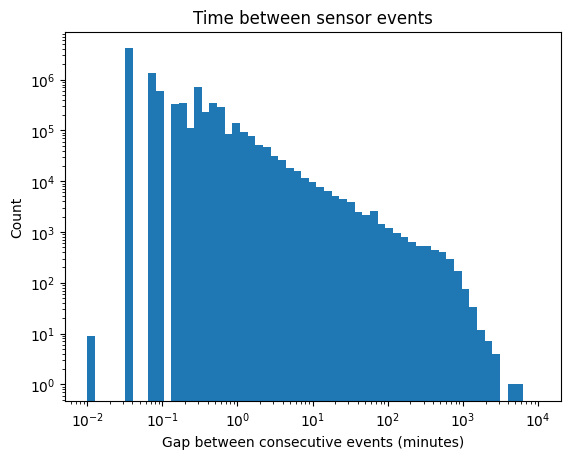

In [8]:
gaps_min = events.groupby("space", observed=True)["time"].diff().dt.total_seconds() / 60
print(gaps_min.describe(percentiles=[0.5, 0.9, 0.99, 0.999]))

plt.hist(gaps_min.dropna().clip(lower=0.01), bins=np.logspace(-2, 4, 60))
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Gap between consecutive events (minutes)"); plt.ylabel("Count")
plt.title("Time between sensor events")
plt.show()

### When did the long silences happen?
Lists all gaps longer than 12 h with their start and end times, to check whether they coincide across spaces (a shared outage) or with known shutdown periods.

In [7]:
long = (events.assign(gap_h=events.groupby("space", observed=True)["time"].diff().dt.total_seconds() / 3600)
              .query("gap_h > 12")
              .assign(gap_start=lambda d: d["time"] - pd.to_timedelta(d["gap_h"], unit="h")))
long[["space", "gap_start", "time", "gap_h"]].sort_values("gap_h", ascending=False).head(20)

,space,gap_start,time,gap_h
5249470,941f0352-bb69-47d0-a9c5-ac29eb4f7319,2023-12-23 10:07:58.000000002+00:00,2024-01-08 01:04:20+00:00,374.939444
36516,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2023-12-23 11:22:58.000000000+00:00,2024-01-08 01:06:38+00:00,373.727778
8772178,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,2025-12-23 18:19:53.999999999+00:00,2025-12-27 09:36:30+00:00,87.276667
1145216,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2024-12-23 03:29:36.000000001+00:00,2024-12-26 06:16:10+00:00,74.776111
1145354,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2024-12-30 18:34:56.000000000+00:00,2025-01-01 21:43:34+00:00,51.143889
6072274,941f0352-bb69-47d0-a9c5-ac29eb4f7319,2024-12-24 12:45:10.000000001+00:00,2024-12-26 13:13:12+00:00,48.467222
6072291,941f0352-bb69-47d0-a9c5-ac29eb4f7319,2024-12-30 18:41:34.000000002+00:00,2025-01-01 16:10:56+00:00,45.489444
8787378,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,2026-01-09 02:24:14.000000000+00:00,2026-01-10 20:26:56+00:00,42.045000
1685307,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2025-08-30 05:42:40.000000000+00:00,2025-08-31 22:00:58+00:00,40.305000
1934026,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2025-12-20 06:19:24.000000002+00:00,2025-12-21 22:31:18+00:00,40.198333


## 5. What state is a space in before a long silence?
For each gap, records the headcount of the event that *starts* the gap, then groups gaps by length. If long silences almost always start from an empty room, the sensor is silent when unoccupied and carrying the last value forward is physically correct.

**Findings:**

| Gap length | Started from headcount 0 |
|---|---|
| 1–6 h | 97.6% |
| 6–12 h | 99.6% |
| > 12 h | 100% |

The sensor reports on change and falls silent when a space is empty.

**Decision: `max_hold = 48 h`.** The last reading is carried forward for up to 48 h, which covers nights and weekends. Silences longer than 48 h (6 cases, up to 15.6 days) are treated as missing, because a shutdown cannot be distinguished from a sensor outage. Limitation: about 180 gaps longer than 1 h began with people present (likely missed exits), and those headcounts are held for up to 48 h. Sensitivity to this choice (12 h / 24 h / 48 h / unlimited) is tested later.

In [5]:
ev = events.assign(next_gap_h=-events.groupby("space", observed=True)["time"].diff(-1).dt.total_seconds() / 3600)
bins = [0, 1, 6, 12, 24, 48, 1000]
summary = (ev.dropna(subset=["next_gap_h"])
             .assign(gap_band=lambda d: pd.cut(d["next_gap_h"], bins),
                     empty_before=lambda d: d["headcount"].eq(0))
             .groupby("gap_band", observed=True)
             .agg(n_gaps=("empty_before", "size"), frac_empty_before=("empty_before", "mean")))
summary

,n_gaps,frac_empty_before
gap_band,,
"(0, 1]",9082595,0.074526
"(1, 6]",7563,0.976068
"(6, 12]",1197,0.995823
"(12, 24]",332,1.000000
"(24, 48]",25,1.000000
"(48, 1000]",6,1.000000


## 6. Resample to a regular 15-minute series
`resample_all` converts each space's irregular events into 15-minute intervals. Between events, the headcount is assumed constant (zero-order hold), and each interval takes the **time-weighted** mean, so a burst of rapid events does not outweigh a long steady period. Binning is done in UTC and converted to Melbourne time afterwards, to avoid errors at daylight-saving changes. Spaces are relabelled A–E because their room mapping is unverified.

The plot shows one mid-semester week as a visual check that the cleaned series looks physically sensible.

Resampled in 4.5 s -> 342,396 intervals
Space A: 0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
Space B: 227f1068-9e41-469f-bef0-275f27a0bdba
Space C: 3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8
Space D: 941f0352-bb69-47d0-a9c5-ac29eb4f7319
Space E: cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b


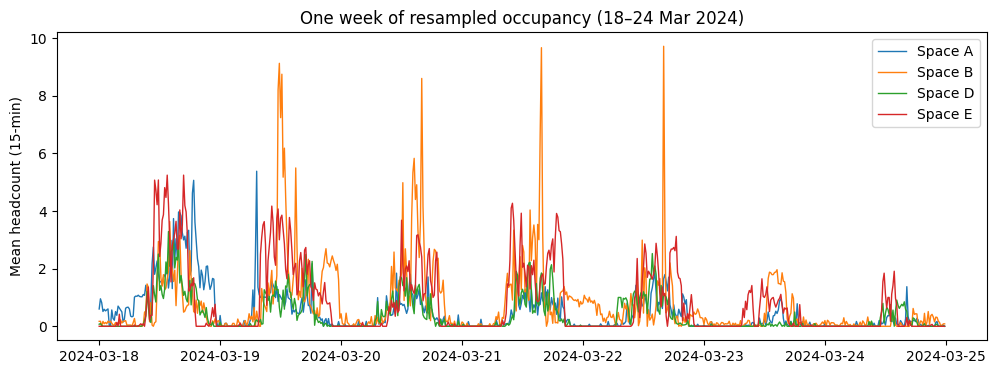

In [10]:
from occforecast.resample import resample_all

t0 = time.perf_counter()
series = resample_all(events, freq="15min", max_hold="48h")
print(f"Resampled in {time.perf_counter() - t0:.1f} s -> {len(series):,} intervals")

# Short labels for plots (IDs are unverified, so keep spaces anonymous)
labels = {s: f"Space {chr(65 + i)}" for i, s in enumerate(sorted(events["space"].unique()))}
series["label"] = series["space"].map(labels)
for s, name in labels.items():
    print(f"{name}: {s}")

week = series.sort_index().loc["2024-03-18":"2024-03-24"]
fig, ax = plt.subplots(figsize=(12, 4))
for name, g in week.groupby("label"):
    ax.plot(g.index, g["headcount_mean"], label=name, lw=1)
ax.set_ylabel("Mean headcount (15-min)")
ax.set_title("One week of resampled occupancy (18–24 Mar 2024)")
ax.legend()
plt.show()

**Findings:** resampling took ≈ 4.5 s for 342,396 intervals. The cleaned series shows a strong daily cycle on weekdays (occupied during the day, near zero overnight) and much lower weekend use. Spaces differ: Space B shows sharp peaks of 9–10 people, suggesting scheduled sessions, while A, D and E mostly stay between 1 and 4. Space C is absent because its data starts on 30 Apr 2024. The strong weekly periodicity suggests a weekday × time-of-day profile will be a reasonable baseline; the short peaks and holiday periods will be the hardest to forecast.